C:\Users\29634\AppData\Local\Temp\ipykernel_5924\29740731.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sales_data1['订单日期'] = sales_data1['订单日期'].str.replace('/','-')


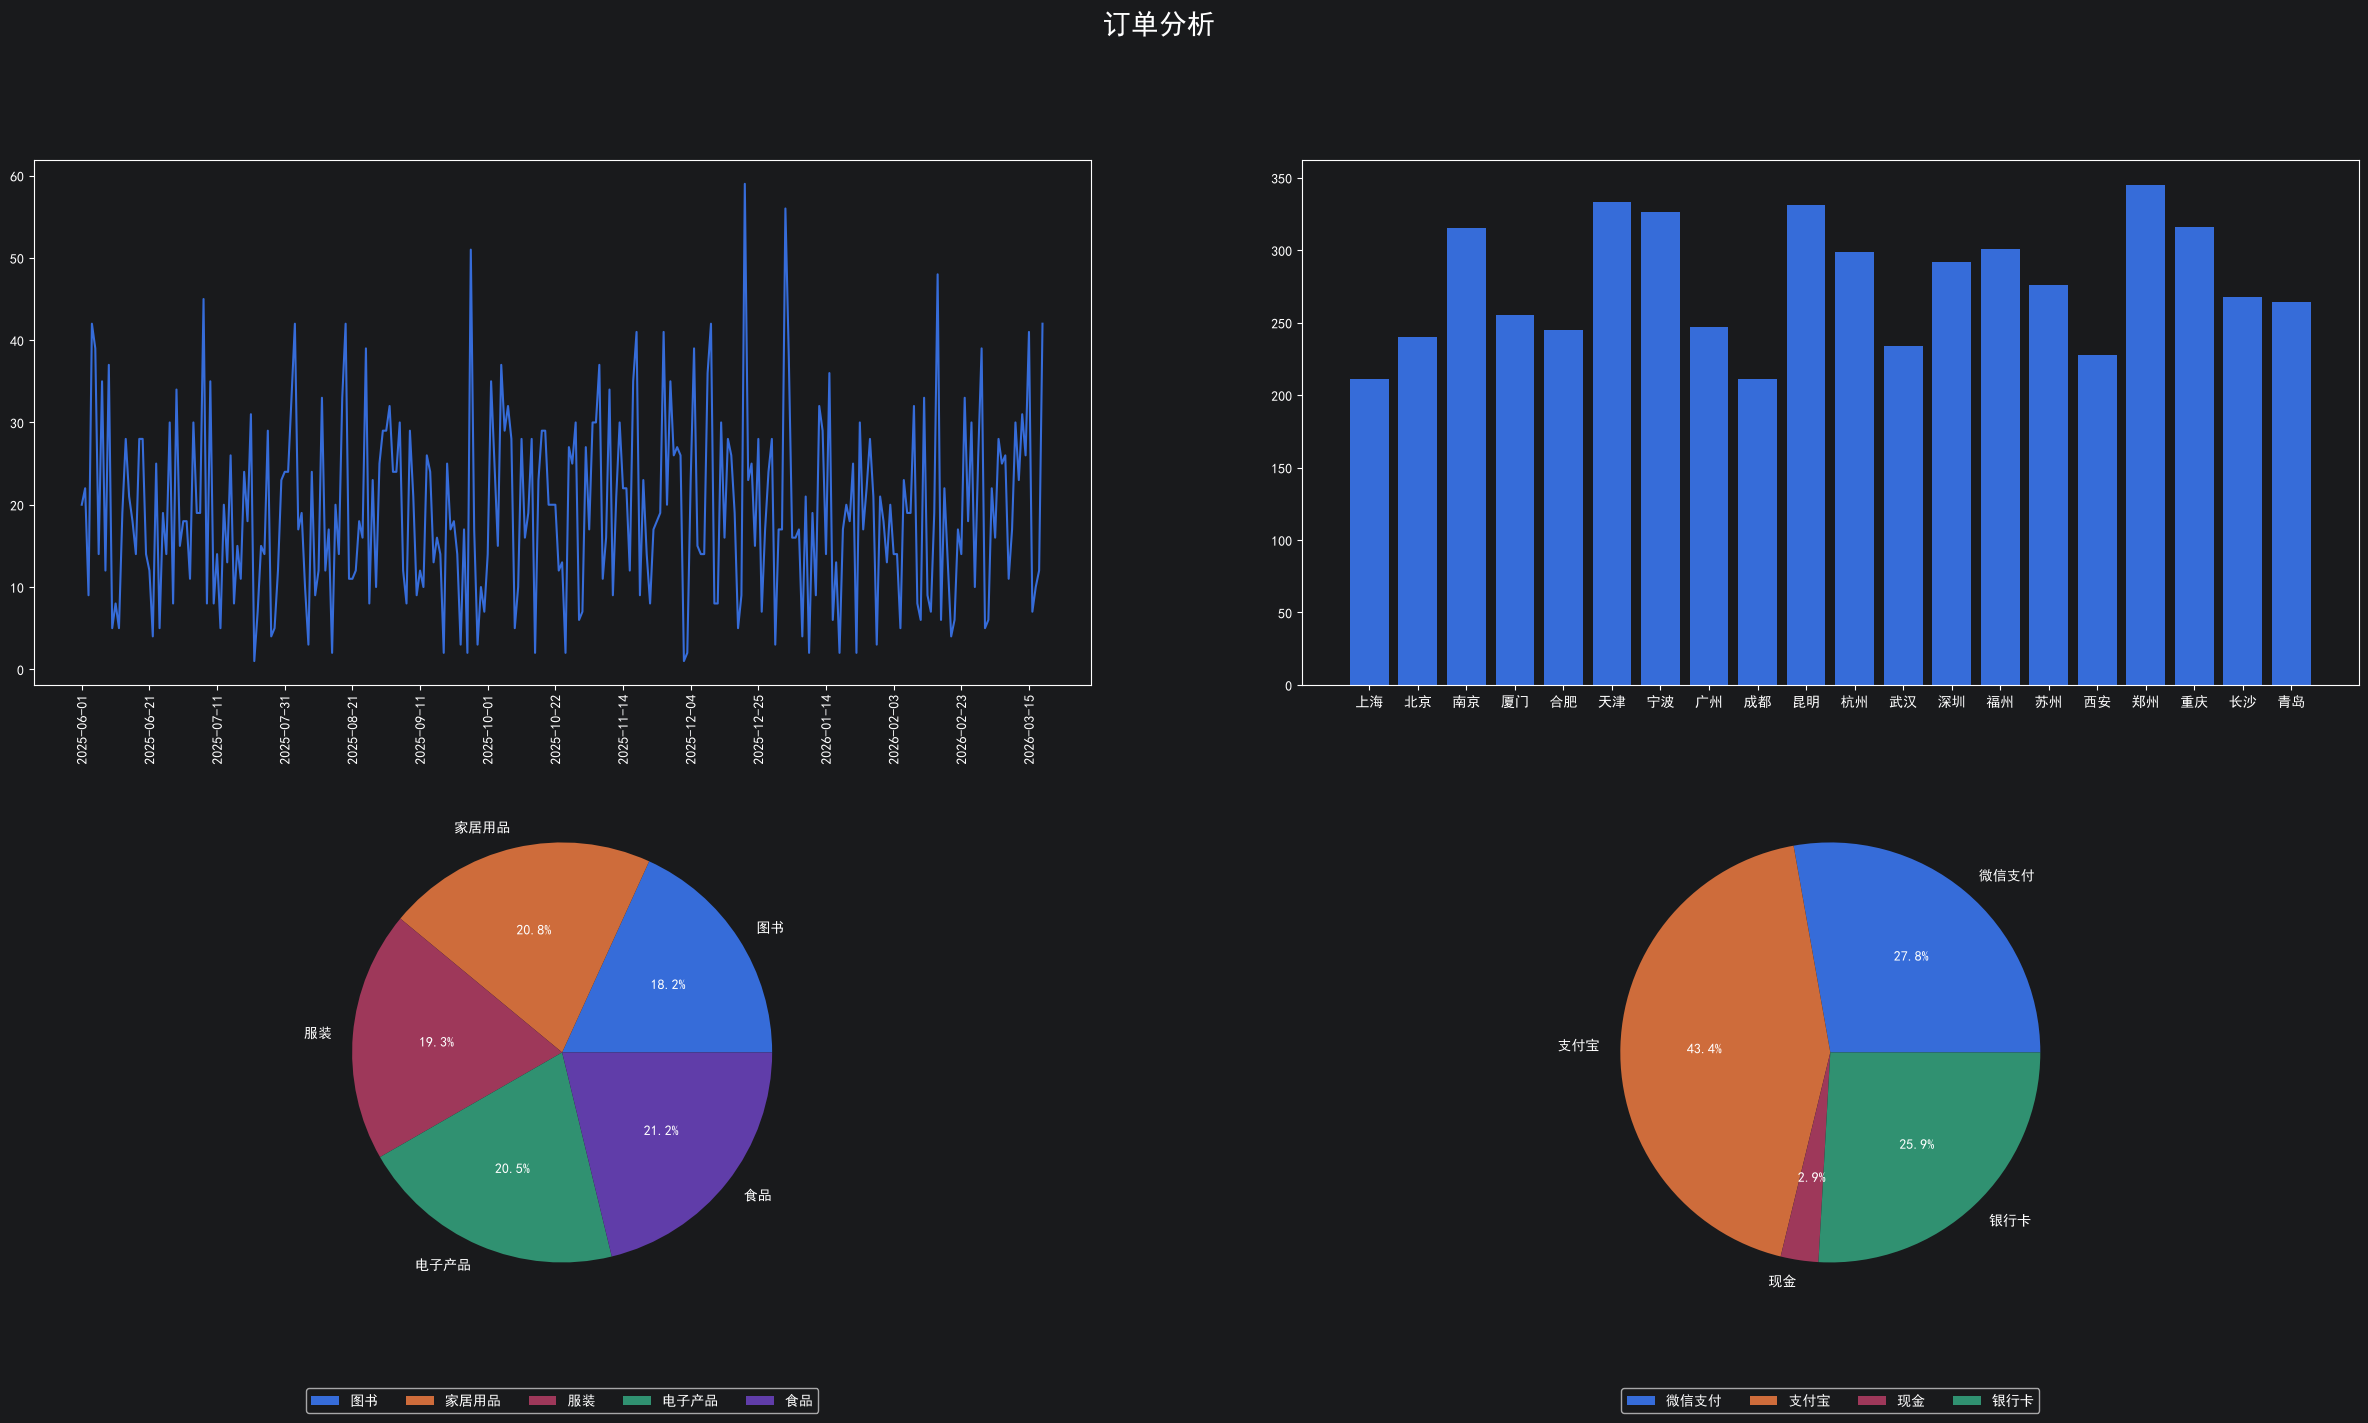

In [46]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.core.pylabtools import figsize

sales_data = pd.read_csv('./resource/sales.csv')
#这个matplotlib库不支持显示中文，需要设置字体
plt.rcParams['font.sans-serif'] = ['SimHei']#设置字体为黑体，解决中文显示问题

#创建子图
fig,ax = plt.subplots(nrows=2,ncols=2,figsize=(30,15))
fig.suptitle('订单分析',fontsize = 20)

#每天销售数量变化
#子图1
#数据
sales_data1 = sales_data[['订单日期','销售数量']]
#处理异常值
sales_data1['订单日期'] = sales_data1['订单日期'].str.replace('/','-')
#统计每一天的销售数量
sales_sum = sales_data1.groupby('订单日期')['销售数量'].sum()
#绘制折线图
ax1 = ax[0,0]
ax1.plot(sales_sum.index,sales_sum.values)
#设置x轴标签数量
ax1.xaxis.set_major_locator(plt.MaxNLocator(20))#maxnlocator最大显示20个标签
#x轴标签旋转90度
ax1.xaxis.set_tick_params(rotation=90)


#每个城市累计销售数量
#子图2
#数据
sales_data2 = sales_data[['客户所在城市','销售数量']]
#处理空值
sales_data2 = sales_data2.dropna()
sales_sum = sales_data2.groupby('客户所在城市')['销售数量'].sum()
ax2 = ax[0,1]
ax2.bar(sales_sum.index,sales_sum.values)



#统计不同类型的产品的订单数量比例
#子图3
#数据
sales_data3 = sales_data[['产品类别','订单号']]
sales_sum2 = sales_data3.groupby('产品类别')['订单号'].count()
sales_sum2
ax3 = ax[1,0]
ax3.pie(sales_sum2.values,labels=sales_sum2.index,autopct='%1.1f%%')
ax3.legend(loc = 'lower center',ncol = 5,bbox_to_anchor = (0.5,-0.2))





#统计不同支付方式的订单数量比例
#子图4
#数据
sales_data4 = sales_data[['支付方式','订单号']]
sales_sum4 = sales_data4.groupby('支付方式')['订单号'].count()
ax4 = ax[1,1]
ax4.pie(sales_sum4.values,labels=sales_sum4.index,autopct='%1.1f%%')
ax4.legend(loc = 'lower center',ncol = 5,bbox_to_anchor = (0.5,-0.2))


